# Exercise 10 - Clustering using K-means on the Olivetti faces dataset

In [1]:
import warnings
warnings.filterwarnings("ignore")

%env OMP_NUM_THREADS=1

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from scipy.io import loadmat
from urllib.request import urlopen
from io import BytesIO
from sklearn.utils import Bunch

env: OMP_NUM_THREADS=1


In [2]:
url = "https://raw.githubusercontent.com/probml/pmtk3/master/bigData/olivettiFaces/olivettiFaces.mat"
mat = loadmat(BytesIO(urlopen(url).read()))

faces = np.asarray(mat["faces"]).T.copy()
faces = faces.astype(np.float32)
faces = (faces - faces.min()) / (faces.max() - faces.min())
faces = faces.reshape(400, 64, 64).transpose(0, 2, 1)

X = faces.reshape(400, -1)
y = np.repeat(np.arange(40), 10)
print(X.shape, y.shape)

(400, 4096) (400,)


In [3]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)
print(X_train.shape, X_val.shape, X_test.shape)

(240, 4096) (80, 4096) (80, 4096)


{10: np.float32(0.095), 20: np.float32(0.103), 30: np.float32(0.119), 40: np.float32(0.139), 50: np.float32(0.16), 60: np.float32(0.178)}


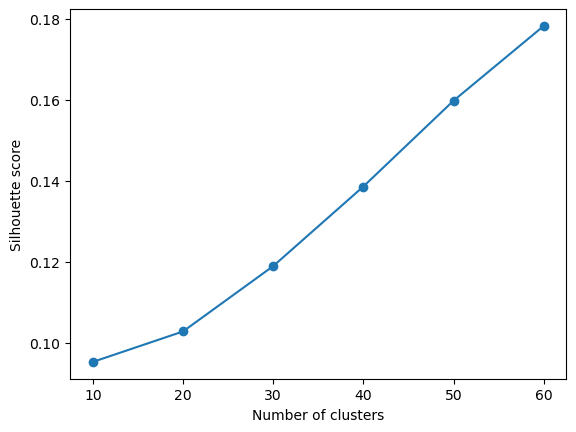

In [4]:
cluster_counts = [10, 20, 30, 40, 50, 60]
scores = []
for k in cluster_counts:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_train)
    scores.append(silhouette_score(X_train, labels))
print(dict(zip(cluster_counts, np.round(scores, 3))))

plt.plot(cluster_counts, scores, "o-")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.show()

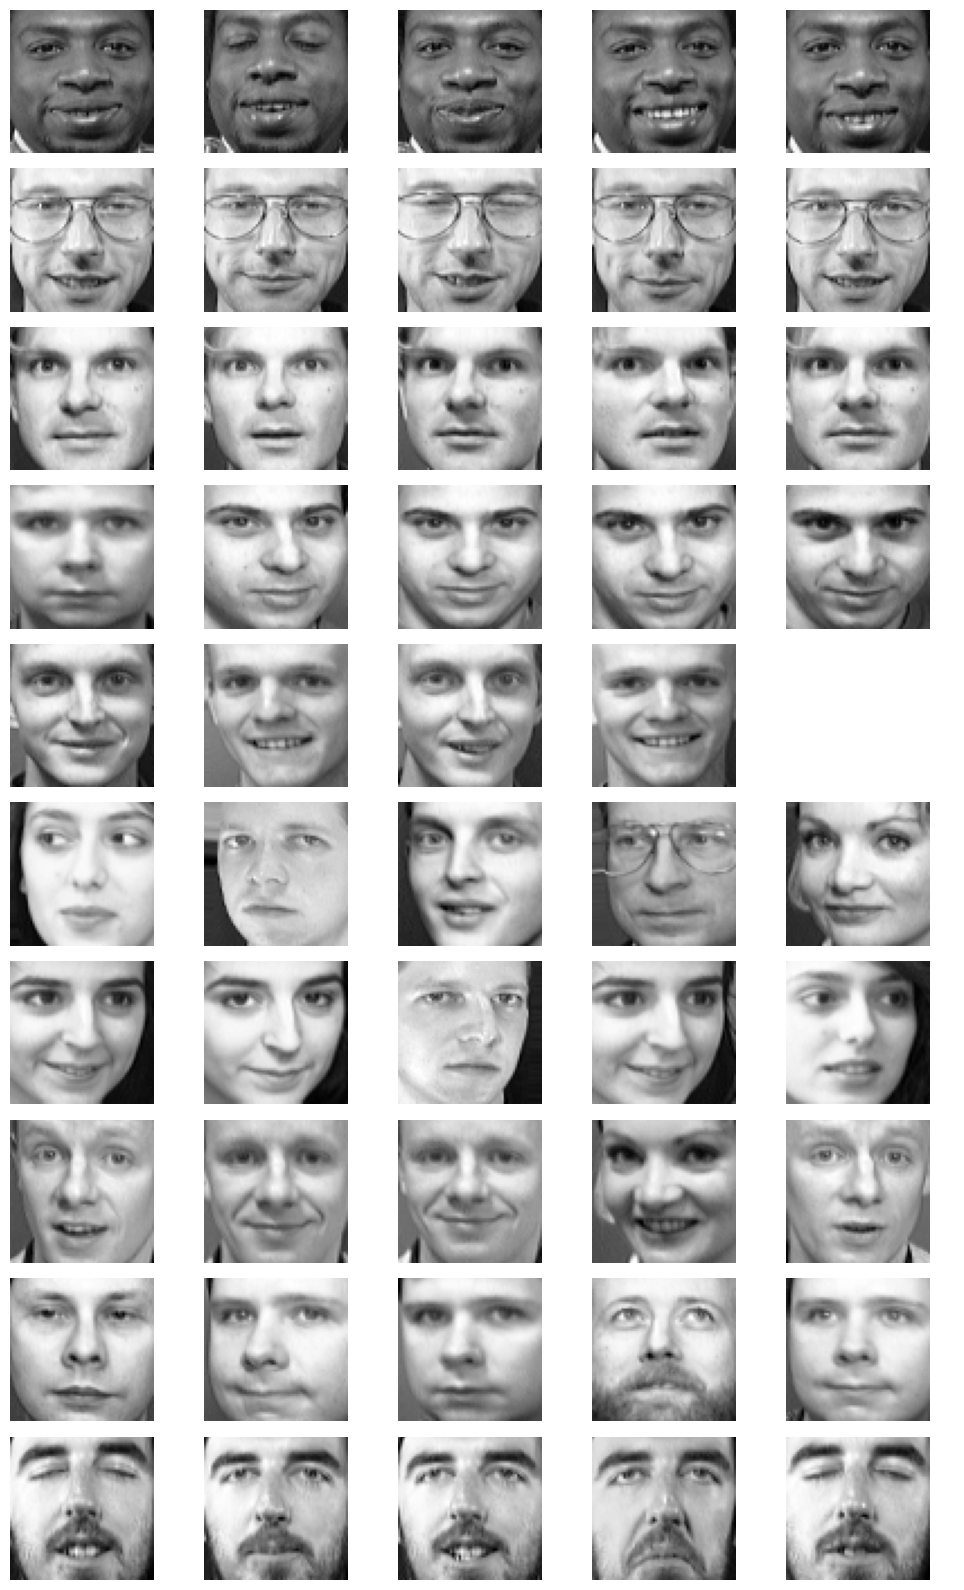

In [5]:
best_k = cluster_counts[np.argmax(scores)]
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(X_train)

fig, axes = plt.subplots(best_k if best_k <= 10 else 10, 5, figsize=(10, 16))
for i, ax_row in enumerate(np.atleast_2d(axes)):
    members = np.where(cluster_labels == i)[0]
    for j, ax in enumerate(ax_row):
        if j < len(members):
            ax.imshow(X_train[members[j]].reshape(64, 64), cmap="gray")
        ax.axis("off")
    ax_row[0].set_ylabel(f"Cluster {i}")
plt.tight_layout()
plt.show()

Silhouette scores represent how separate the clusters are but not the grouping inside the cluster. K-means has done a decent job in clustering faces though there are few groups which have mixed faces.

# Exercise 11 - Classify faces with and without K-means features

In [6]:
base_model = SVC(kernel="rbf", C=10, gamma="scale")
base_model.fit(X_train, y_train)
base_acc = accuracy_score(y_val, base_model.predict(X_val))
print("Original-feature validation accuracy:", round(base_acc, 3))

Original-feature validation accuracy: 0.938


In [7]:
cluster_counts = [10, 20, 40, 60, 80, 100]
results = []

for k in cluster_counts:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    Z_train = km.fit_transform(X_train)
    Z_val = km.transform(X_val)

    reduced_model = SVC(kernel="rbf", C=10, gamma="scale")
    reduced_model.fit(Z_train, y_train)
    reduced_acc = accuracy_score(y_val, reduced_model.predict(Z_val))

    combined_model = SVC(kernel="rbf", C=10, gamma="scale")
    combined_model.fit(np.hstack([X_train, Z_train]), y_train)
    combined_acc = accuracy_score(y_val, combined_model.predict(np.hstack([X_val, Z_val]))    )
    results.append((k, reduced_acc, combined_acc))

for row in results:
    print(f"k={row[0]:3d} | reduced={row[1]:.3f} | combined={row[2]:.3f}")

best_reduced = max(results, key=lambda r: r[1])
best_combined = max(results, key=lambda r: r[2])
print("Best reduced features:", best_reduced)
print("Best combined features:", best_combined)

k= 10 | reduced=0.650 | combined=0.925
k= 20 | reduced=0.750 | combined=0.863
k= 40 | reduced=0.775 | combined=0.725
k= 60 | reduced=0.838 | combined=0.713
k= 80 | reduced=0.812 | combined=0.675
k=100 | reduced=0.838 | combined=0.675
Best reduced features: (60, 0.8375, 0.7125)
Best combined features: (10, 0.65, 0.925)


- K-means is normally a clustering algorithm, but here we're using it to create new features for classification. Each face has 4,096 original pixel features. K-means learns 10 cluster centres, each representing a typical location in pixel space. fit_transform() calculates each training face's distance to all 10 centres. So the face is now represented by 10 distances instead of 4,096 pixel values.
- With 10 clusters, each face is represented by only 10 distances. That's a very compressed representation of 4,096 pixel values, so the classifier loses a lot of detail. Increasing k gives the model more features to work with. The improvement isn't perfectly monotonic because adding clusters doesn't guarantee that the new features are useful for identifying people.
- The original pixels already contain detailed facial information. The extra cluster-distance features may be redundant, and adding them changes the geometry used by the RBF SVM. This suggests that for the current setup, the extra features are not helping the classifier.

# Exercise 12 - Using Gaussian mixture model to generate faces and detect anomalies

In [8]:
pca = PCA(n_components=0.99, svd_solver="full", random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_val_pca = pca.transform(X_val)
print("PCA features:", X_train_pca.shape[1])

gmm = GaussianMixture(n_components=40, covariance_type="diag", reg_covar=1e-4, n_init=2, max_iter=200, random_state=42)
gmm.fit(X_train_pca)
print("Converged:", gmm.converged_)

PCA features: 177
Converged: True


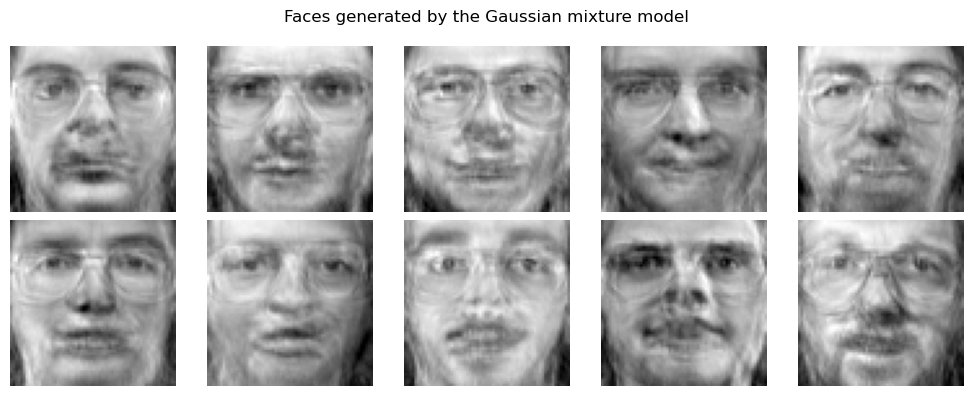

In [9]:
samples, _ = gmm.sample(10)
generated_faces = pca.inverse_transform(samples).clip(0, 1)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, face in zip(axes.ravel(), generated_faces):
    ax.imshow(face.reshape(64, 64), cmap="gray")
    ax.axis("off")
plt.suptitle("Faces generated by the Gaussian mixture model")
plt.tight_layout()
plt.show()

In [10]:
normal = X_val[:10].reshape(-1, 64, 64)
flipped = np.fliplr(normal)
rotated = np.rot90(normal, k=1, axes=(1, 2))
darkened = normal * 0.5

anomalies = np.concatenate([flipped.reshape(-1, 4096), rotated.reshape(-1, 4096), darkened.reshape(-1, 4096)])
X_anom_pca = pca.transform(anomalies)

normal_scores = gmm.score_samples(X_val_pca)
anomaly_scores = gmm.score_samples(X_anom_pca)

print("Mean normal log-likelihood:", round(normal_scores.mean(), 3))
print("Mean modified-image log-likelihood:", round(anomaly_scores.mean(), 3))
print("Normal 10th percentile:", round(np.percentile(normal_scores, 10), 3))
print("Anomaly 90th percentile:", round(np.percentile(anomaly_scores, 90), 3))

Mean normal log-likelihood: -35.009
Mean modified-image log-likelihood: -198.344
Normal 10th percentile: -88.485
Anomaly 90th percentile: -51.028


- A Gaussian mixture assigns higher log-likelihood to images that look more probable under its learned distribution. The modified images here have a much lower mean log-likelihood, suggesting they are less typical of the training faces.
- The normal and anomaly percentile ranges overlap. The averages show a strong difference, but they do not prove perfect separation.
- A lower score means a more unusual image according to this model, not necessarily a genuinely invalid face.

# Exercise 13 - PCA reconstruction error for anomaly detection

In [11]:
pca_recon = PCA(n_components=0.99, svd_solver="full", random_state=42)
pca_recon.fit(X_train)

def reconstruction_error(model, X):
    X_reconstructed = model.inverse_transform(model.transform(X))
    errors = np.mean((X - X_reconstructed) ** 2, axis=1)
    return errors, X_reconstructed

normal_errors, normal_recon = reconstruction_error(pca_recon, X_val)
anomaly_errors, anomaly_recon = reconstruction_error(pca_recon, anomalies)

print("Mean normal reconstruction error:", round(normal_errors.mean(), 5))
print("Mean modified-image reconstruction error:", round(anomaly_errors.mean(), 5))
print("Normal 95th percentile:", round(np.percentile(normal_errors, 95), 5))
print("Anomaly median:", round(np.median(anomaly_errors), 5))

Mean normal reconstruction error: 0.00225
Mean modified-image reconstruction error: 0.00616
Normal 95th percentile: 0.00488
Anomaly median: 0.00676


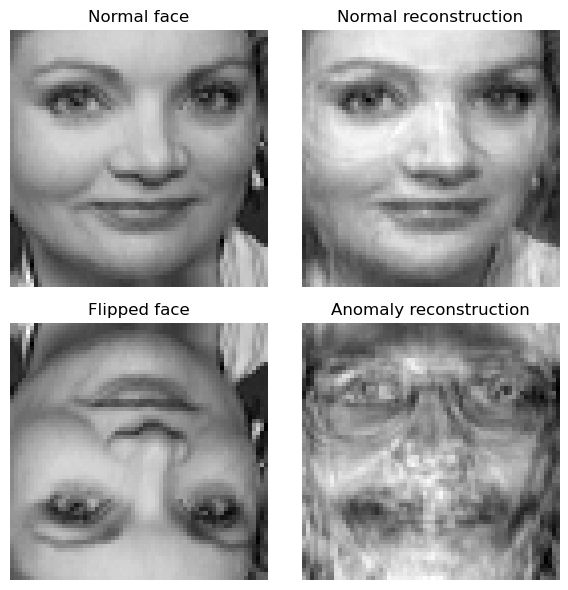

In [12]:
i = 0
fig, axes = plt.subplots(2, 2, figsize=(6, 6))
axes[0, 0].imshow(X_val[i].reshape(64, 64), cmap="gray")
axes[0, 0].set_title("Normal face")
axes[0, 1].imshow(normal_recon[i].reshape(64, 64), cmap="gray")
axes[0, 1].set_title("Normal reconstruction")
axes[1, 0].imshow(anomalies[i].reshape(64, 64), cmap="gray")
axes[1, 0].set_title("Flipped face")
axes[1, 1].imshow(anomaly_recon[i].reshape(64, 64), cmap="gray")
axes[1, 1].set_title("Anomaly reconstruction")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

- The mean error for modified images is about 2.74 times the normal mean error. PCA learns a lower-dimensional subspace that captures the main variation in ordinary faces. When an image is projected into that subspace and reconstructed, details that don't fit the learned patterns are lost. Modified faces may contain more of those unusual patterns, producing larger reconstruction errors.
- PCA reconstruction errors were larger for modified faces, making reconstruction error a potentially useful anomaly score.